# A Vida de uma Inteligência Artificial

Do texto bruto ao modelo generativo: como uma rede neural **aprende**, **guarda** o que aprendeu e **responde**.

Neste notebook acompanhamos uma IA em dez etapas, da transformação de texto em números até a multimodalidade. Tudo roda em **CPU**, com experimentos pequenos e reproduzíveis.

Os modelos aqui são *de brinquedo*: servem para enxergar o mecanismo. Os LLMs reais usam as mesmas ideias em escala muito maior, e avisaremos sempre que uma demonstração for simplificada.

| Capítulo | Tema |
|---|---|
| 1 | O nascimento da IA |
| 2 | Texto em números |
| 3 | Arquitetura Transformer |
| 4 | Treinamento |
| 5 | Armazenamento do aprendizado |
| 6 | Fine-tuning |
| 7 | Inferência |
| 8 | Generative AI |
| 9 | Multimodalidade |
| 10 | Ciclo de vida da IA |

## Preparação do ambiente

**Dependências obrigatórias:** `numpy`, `torch` (versão CPU basta) e `matplotlib`.
**Opcional:** `transformers`, usada apenas para comparar com um tokenizador real (capítulo 2). Ela fica desligada por padrão.

```bash
pip install numpy torch matplotlib
```

In [1]:
import math
import os
import re
import tempfile
import time
from collections import Counter
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SEMENTE = 42
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)

# Ligue para comparar com um tokenizador real (exige `pip install transformers` e internet).
USAR_HUGGINGFACE = False

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print(f"numpy {np.__version__} | torch {torch.__version__} | GPU disponível: {torch.cuda.is_available()}")

numpy 2.5.1 | torch 2.13.0+cpu | GPU disponível: False


# 1. O nascimento da IA

A **Inteligência Artificial** busca fazer máquinas executarem tarefas que exigem inteligência humana. Dentro dela há camadas: o **Machine Learning** aprende regras a partir de exemplos, o **Deep Learning** faz isso com redes neurais de muitas camadas, e os **LLMs** são redes gigantes, em geral Transformers, treinadas para prever a próxima palavra.

A unidade básica dessas redes é o **neurônio**. Ele multiplica as entradas por pesos, soma um viés (*bias*) e aplica uma função de ativação, que permite à rede aprender relações não lineares.

$$ saída = f(w_1 x_1 + w_2 x_2 + b) $$

Os pesos e o viés são os **parâmetros**: é neles que a IA guarda o que aprendeu. Abaixo, as camadas da IA, as funções de ativação mais comuns e um neurônio calculado à mão.

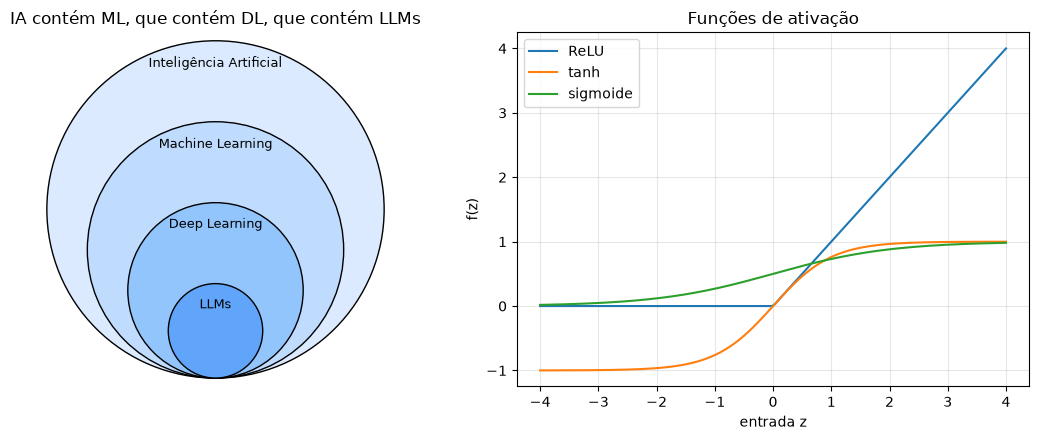

z = 0.8*1.0 + -0.4*0.5 + 0.1 = 0.70
saída com sigmoide = 0.668


In [2]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))

# Camadas da IA como círculos aninhados
ax = eixos[0]
camadas = [(1.00, "Inteligência Artificial", "#dbeafe"), (0.76, "Machine Learning", "#bfdbfe"),
           (0.52, "Deep Learning", "#93c5fd"), (0.28, "LLMs", "#60a5fa")]
for raio, nome, cor in camadas:
    ax.add_patch(plt.Circle((0, raio - 1), raio, fc=cor, ec="k"))
    ax.text(0, 2 * raio - 1 - 0.09, nome, ha="center", va="top", fontsize=9)
ax.set(xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), aspect="equal", title="IA contém ML, que contém DL, que contém LLMs")
ax.axis("off")

# Funções de ativação
ax = eixos[1]
z = np.linspace(-4, 4, 200)
ax.plot(z, np.maximum(0, z), label="ReLU")
ax.plot(z, np.tanh(z), label="tanh")
ax.plot(z, 1 / (1 + np.exp(-z)), label="sigmoide")
ax.set(title="Funções de ativação", xlabel="entrada z", ylabel="f(z)")
ax.legend()
plt.tight_layout()
plt.show()

# Um neurônio com dois pesos
entradas = np.array([1.0, 0.5])
pesos = np.array([0.8, -0.4])
vies = 0.1
z = pesos @ entradas + vies
print(f"z = {pesos[0]}*{entradas[0]} + {pesos[1]}*{entradas[1]} + {vies} = {z:.2f}")
print(f"saída com sigmoide = {1 / (1 + np.exp(-z)):.3f}")

**Interpretação.** O neurônio calculou $z = 0{,}7$ e a sigmoide levou esse valor para entre 0 e 1. As ativações não são retas de propósito: sem elas, empilhar camadas equivaleria a uma única conta linear.

Uma rede é feita de muitos neurônios assim. Resta saber como encontrar bons valores para os pesos, e essa é a pergunta que guia o resto do notebook.

# 2. Texto em números

Redes neurais só entendem números. Por isso o texto passa por três etapas: a **tokenização** quebra o texto em pedaços (*tokens*), o **vocabulário** dá um ID inteiro a cada token, e os **embeddings** transformam cada ID em um vetor ajustável.

A tokenização mais simples separa por palavras. O custo é que qualquer palavra fora do vocabulário vira `<unk>`.

In [3]:
corpus = [
    "o gato dorme no sofá", "o cachorro dorme no tapete",
    "o gato come o peixe", "o cachorro come a carne",
    "a menina lê o livro", "o menino lê o jornal",
    "a menina come a maçã", "o menino come o pão",
]

palavras = sorted({p for frase in corpus for p in frase.split()})
vocab = {"<pad>": 0, "<unk>": 1, **{p: i + 2 for i, p in enumerate(palavras)}}


def tokenizar(frase):
    return [vocab.get(p, vocab["<unk>"]) for p in frase.split()]


print(f"Vocabulário com {len(vocab)} tokens")
for frase in ["o gato come a carne", "o gato bebe leite"]:
    print(f"{frase!r:25} -> {tokenizar(frase)}")

Vocabulário com 20 tokens
'o gato come a carne'     -> [15, 7, 5, 2, 4]
'o gato bebe leite'       -> [15, 7, 1, 1]


**Interpretação.** "bebe" e "leite" não estavam no vocabulário e viraram o ID `1`: a informação se perdeu.

LLMs reais usam **subpalavras**, como no *Byte-Pair Encoding* (BPE). O algoritmo parte de caracteres e funde, repetidamente, o par mais frequente. Palavras comuns viram um token só, e palavras raras são montadas com pedaços conhecidos. Veja um BPE minúsculo.

In [4]:
def aprender_bpe(palavras, n_fusoes):
    sequencias = [list(p) + ["</w>"] for p in palavras]
    fusoes = []
    for _ in range(n_fusoes):
        pares = Counter()
        for seq in sequencias:
            pares.update(zip(seq, seq[1:]))
        if not pares:
            break
        a, b = pares.most_common(1)[0][0]
        fusoes.append((a, b))
        novas = []
        for seq in sequencias:
            nova, i = [], 0
            while i < len(seq):
                if i < len(seq) - 1 and (seq[i], seq[i + 1]) == (a, b):
                    nova.append(a + b)
                    i += 2
                else:
                    nova.append(seq[i])
                    i += 1
            novas.append(nova)
        sequencias = novas
    return fusoes, sequencias


amostra = ["token"] * 5 + ["tokens"] * 3 + ["tokenizar"] * 2 + ["realizar"] * 2 + ["generalizar"] * 2
fusoes, segmentadas = aprender_bpe(amostra, n_fusoes=12)

print("Primeiras fusões aprendidas:", [a + b for a, b in fusoes[:6]])
for palavra in dict.fromkeys(amostra):
    print(f"{palavra:12} -> {segmentadas[amostra.index(palavra)]}")

Primeiras fusões aprendidas: ['en', 'to', 'tok', 'token', 'iz', 'iza']
token        -> ['token</w>']
tokens       -> ['tokens', '</w>']
tokenizar    -> ['token', 'izar</w>']
realizar     -> ['r', 'e', 'alizar</w>']
generalizar  -> ['g', 'en', 'e', 'r', 'alizar</w>']


**Interpretação.** O algoritmo descobriu sozinho pedaços reutilizáveis, como `token` e `izar</w>`. Assim, uma palavra nova como "tokenizador" pode ser montada com partes que o modelo já conhece. Vocabulários reais têm de 30 mil a 200 mil tokens.

Depois dos IDs, cada token indexa uma linha da **tabela de embeddings**, que é o seu vetor. Esses vetores são parâmetros que a rede aprende, e no início são aleatórios. Vamos compará-los antes e depois de um treino curto, em que o modelo prevê as palavras vizinhas (a ideia do *word2vec*).

In [5]:
dim_emb = 8
torch.manual_seed(SEMENTE)
embedding = nn.Embedding(len(vocab), dim_emb)

ids = torch.tensor(tokenizar("o gato come a carne"))
print("IDs:", ids.tolist())
print("Formato dos vetores:", tuple(embedding(ids).shape), "(tokens, dimensões)")
print("Vetor do token 'gato':", embedding.weight[vocab["gato"]].detach().numpy().round(2))


def pares_vizinhos(corpus, janela=2):
    pares = []
    for frase in corpus:
        t = tokenizar(frase)
        for i, alvo in enumerate(t):
            for j in range(max(0, i - janela), min(len(t), i + janela + 1)):
                if j != i:
                    pares.append((alvo, t[j]))
    return torch.tensor(pares)


def similaridade(par):
    a, b = (embedding.weight[vocab[p]] for p in par)
    return F.cosine_similarity(a, b, dim=0).item()


pares_teste = [("gato", "cachorro"), ("menina", "menino"), ("gato", "livro")]
antes = [similaridade(p) for p in pares_teste]
emb_antes = embedding.weight.detach().clone()

# Treino curto: prever a palavra vizinha a partir do embedding da palavra central
cabeca = nn.Linear(dim_emb, len(vocab))
otimizador = torch.optim.Adam(list(embedding.parameters()) + list(cabeca.parameters()), lr=0.05)
dados = pares_vizinhos(corpus)
for _ in range(300):
    perda = F.cross_entropy(cabeca(embedding(dados[:, 0])), dados[:, 1])
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()

depois = [similaridade(p) for p in pares_teste]
print(f"\nPerda final do treino de embeddings: {perda.item():.3f}")
print(f"{'par':22}{'antes':>8}{'depois':>8}")
for p, a, d in zip(pares_teste, antes, depois):
    print(f"{p[0] + ' ~ ' + p[1]:22}{a:8.2f}{d:8.2f}")

IDs: [15, 7, 5, 2, 4]
Formato dos vetores: (5, 8) (tokens, dimensões)
Vetor do token 'gato': [-1.4   0.04 -0.06  0.68 -0.1   1.84 -1.18  1.38]



Perda final do treino de embeddings: 1.607
par                      antes  depois
gato ~ cachorro           0.09    0.81
menina ~ menino           0.45    0.57
gato ~ livro              0.11    0.19


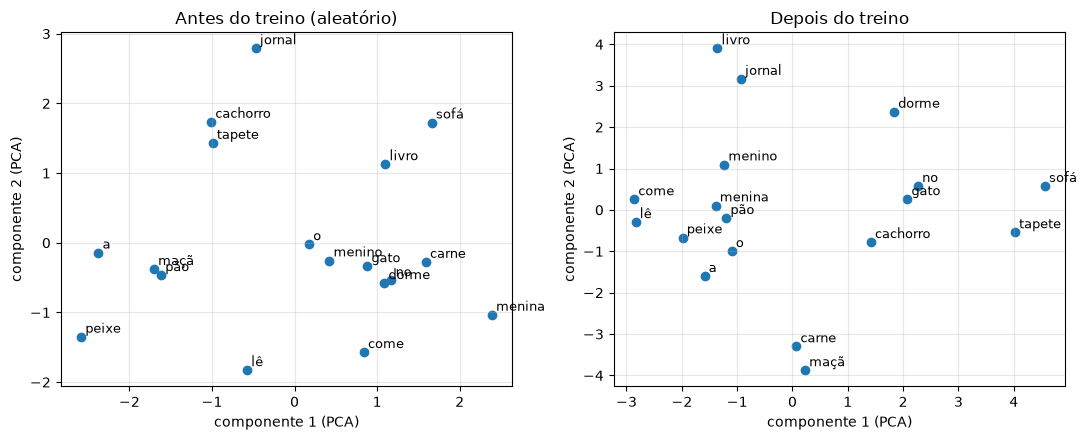

In [6]:
def projetar_2d(matriz):
    centrada = matriz - matriz.mean(0)
    _, _, vt = torch.linalg.svd(centrada, full_matrices=False)
    return centrada @ vt[:2].T


reais = [p for p in vocab if not p.startswith("<")]
indices = [vocab[p] for p in reais]
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5), sharex=False)
for ax, pesos, titulo in [(eixos[0], emb_antes, "Antes do treino (aleatório)"),
                          (eixos[1], embedding.weight.detach(), "Depois do treino")]:
    xy = projetar_2d(pesos[indices])
    ax.scatter(xy[:, 0], xy[:, 1])
    for (x, y), p in zip(xy, reais):
        ax.annotate(p, (x, y), fontsize=9, xytext=(3, 3), textcoords="offset points")
    ax.set(title=titulo, xlabel="componente 1 (PCA)", ylabel="componente 2 (PCA)")
plt.tight_layout()
plt.show()

**Interpretação.** Antes do treino, as similaridades são sorteios aleatórios. Depois, "gato" e "cachorro", que aparecem em contextos parecidos, ficam muito mais próximos (0,09 → 0,81), enquanto "gato" e "livro" continuam distantes. "menina" e "menino" também se aproximam, mas pouco: com tão poucas frases, o sinal é fraco.

O significado surgiu da vizinhança entre as palavras, sem que ninguém o ensinasse. Em LLMs reais, os embeddings têm milhares de dimensões e são treinados junto com a rede, com trilhões de tokens (aqui são 8 frases).

Falta a ordem. O Transformer lê todos os tokens ao mesmo tempo, então "o gato come o peixe" e "o peixe come o gato" teriam os mesmos vetores. A solução é somar a cada embedding uma **codificação posicional**, que na versão original usa senos e cossenos.

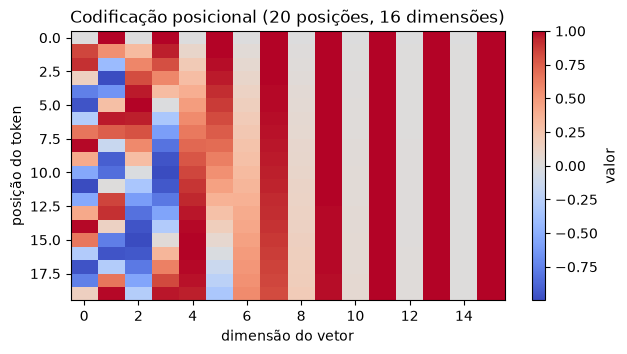

In [7]:
def codificacao_posicional(n_posicoes, dim):
    pos = torch.arange(n_posicoes).unsqueeze(1)
    freq = torch.exp(-math.log(10000.0) * torch.arange(0, dim, 2) / dim)
    pe = torch.zeros(n_posicoes, dim)
    pe[:, 0::2] = torch.sin(pos * freq)
    pe[:, 1::2] = torch.cos(pos * freq)
    return pe


pe = codificacao_posicional(20, 16)
plt.figure(figsize=(7, 3.5))
plt.imshow(pe, aspect="auto", cmap="coolwarm")
plt.colorbar(label="valor")
plt.title("Codificação posicional (20 posições, 16 dimensões)")
plt.xlabel("dimensão do vetor")
plt.ylabel("posição do token")
plt.grid(False)
plt.show()

**Interpretação.** Cada linha é uma "impressão digital" da posição: as primeiras dimensões oscilam rápido e as últimas devagar, como ponteiros de segundos e de horas. Assim o modelo distingue a ordem das palavras.

*(Opcional)* Com `USAR_HUGGINGFACE = True`, o tokenizador do GPT-2 (cerca de 1 MB) mostra o BPE em escala real.

In [8]:
if USAR_HUGGINGFACE:
    try:
        from transformers import AutoTokenizer

        tok = AutoTokenizer.from_pretrained("gpt2")
        frase = "A tokenização transforma texto em números."
        print(tok.tokenize(frase))
        print(tok(frase)["input_ids"])
    except Exception as erro:
        print("Célula opcional ignorada:", erro)
else:
    print("Célula opcional desligada (USAR_HUGGINGFACE = False).")

Célula opcional desligada (USAR_HUGGINGFACE = False).


# 3. Arquitetura Transformer

Antes do Transformer, redes recorrentes liam o texto palavra por palavra e "esqueciam" o começo de frases longas. O Transformer troca isso pela **Self-Attention**: cada token olha para todos os outros de uma vez e decide quanto prestar atenção em cada um.

Para isso, cada token gera três vetores, a partir de matrizes de pesos aprendidas: a **Query** (o que ele procura), a **Key** (o que ele oferece) e o **Value** (a informação que ele entrega). Comparar Queries com Keys gera *scores*, a softmax os transforma em pesos que somam 1, e esses pesos misturam os Values. A divisão por $\sqrt{d_k}$ mantém os scores em escala estável.

$$ \text{Atenção}(Q,K,V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V $$

No exemplo, Wq, Wk e Wv são aleatórios, porque o que importa agora é o mecanismo. O aprendizado desses pesos fica para o capítulo 4.

X: (4, 8) | saída: (4, 4)
Soma de cada linha dos pesos: [1. 1. 1. 1.]


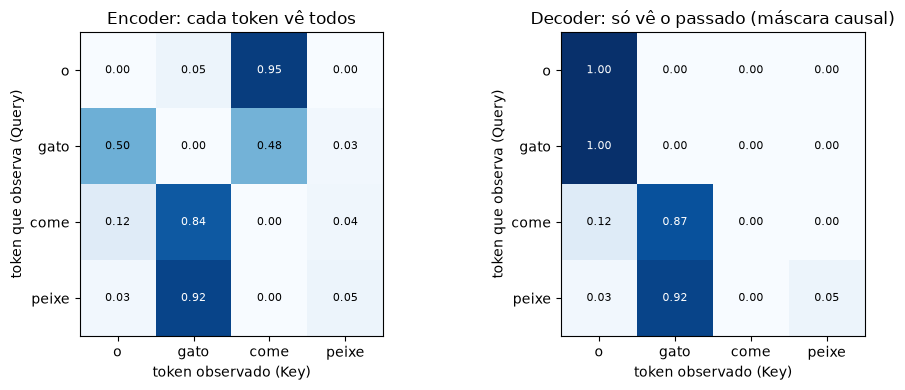

In [9]:
def mapa_calor(ax, matriz, rotulos_x, rotulos_y, titulo):
    img = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(rotulos_x)), rotulos_x)
    ax.set_yticks(range(len(rotulos_y)), rotulos_y)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            ax.text(j, i, f"{matriz[i, j]:.2f}", ha="center", va="center",
                    color="white" if matriz[i, j] > 0.5 else "black", fontsize=8)
    ax.set_title(titulo)
    ax.grid(False)
    return img


def atencao(X, Wq, Wk, Wv, causal=False):
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    scores = Q @ K.T / math.sqrt(K.shape[-1])
    if causal:
        futuro = torch.triu(torch.ones_like(scores), diagonal=1).bool()
        scores = scores.masked_fill(futuro, float("-inf"))
    pesos = F.softmax(scores, dim=-1)
    return pesos @ V, pesos


tokens = ["o", "gato", "come", "peixe"]
d_modelo, d_k = 8, 4
torch.manual_seed(SEMENTE)
X = torch.randn(len(tokens), d_modelo)  # embeddings + posição (fictícios)
Wq, Wk, Wv = (torch.randn(d_modelo, d_k) * 0.7 for _ in range(3))

saida, pesos_atencao = atencao(X, Wq, Wk, Wv)
print("X:", tuple(X.shape), "| saída:", tuple(saida.shape))
print("Soma de cada linha dos pesos:", pesos_atencao.sum(dim=-1).numpy().round(3))

_, pesos_causal = atencao(X, Wq, Wk, Wv, causal=True)
fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
mapa_calor(eixos[0], pesos_atencao.numpy(), tokens, tokens, "Encoder: cada token vê todos")
mapa_calor(eixos[1], pesos_causal.numpy(), tokens, tokens, "Decoder: só vê o passado (máscara causal)")
for ax in eixos:
    ax.set(xlabel="token observado (Key)", ylabel="token que observa (Query)")
plt.tight_layout()
plt.show()

**Interpretação.** Cada linha mostra como um token distribui sua atenção, e todas somam 1. Os pesos são aleatórios, então os padrões não têm sentido linguístico. Após o treino, esses mecanismos passam a ligar, por exemplo, um verbo ao seu sujeito.

A diferença entre os gráficos é a **máscara causal**. No *encoder* (como o BERT), cada token vê a frase inteira, o que serve para *entender* texto. No *decoder* (como o GPT), cada token só vê os anteriores, o que permite *gerar* texto uma palavra por vez, sem "colar" do futuro.

Uma única atenção observa um tipo de relação por vez. A **Multi-Head Attention** roda várias em paralelo, cada uma com seus próprios Wq, Wk e Wv, e concatena os resultados.

Cada cabeça: (4, 4) | concatenadas: (4, 8) | saída final: (4, 8)


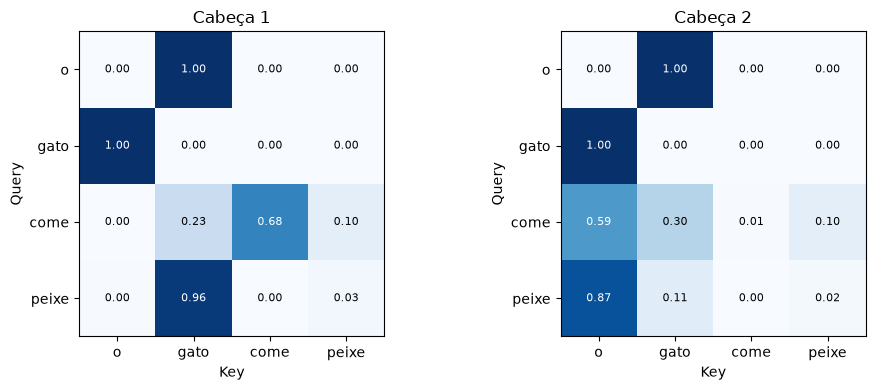

In [10]:
n_cabecas = 2
torch.manual_seed(SEMENTE)
cabecas = [tuple(torch.randn(d_modelo, d_k) * 0.7 for _ in range(3)) for _ in range(n_cabecas)]
Wo = torch.randn(n_cabecas * d_k, d_modelo) * 0.7

saidas, mapas = [], []
for Wq_h, Wk_h, Wv_h in cabecas:
    s, p = atencao(X, Wq_h, Wk_h, Wv_h)
    saidas.append(s)
    mapas.append(p)

multi_cabeca = torch.cat(saidas, dim=-1) @ Wo
print("Cada cabeça:", tuple(saidas[0].shape), "| concatenadas:", tuple(torch.cat(saidas, -1).shape),
      "| saída final:", tuple(multi_cabeca.shape))

fig, eixos = plt.subplots(1, n_cabecas, figsize=(10, 4))
for i, ax in enumerate(eixos):
    mapa_calor(ax, mapas[i].numpy(), tokens, tokens, f"Cabeça {i + 1}")
    ax.set(xlabel="Key", ylabel="Query")
plt.tight_layout()
plt.show()

**Interpretação.** As duas cabeças olham os mesmos tokens e geram mapas diferentes. A saída final tem o mesmo formato da entrada, o que permite empilhar muitos blocos iguais.

Um **bloco Transformer** completo soma à atenção uma rede *feed-forward*, conexões residuais e normalização (*LayerNorm*). Um LLM é uma pilha de dezenas desses blocos. Usamos o bloco pronto do PyTorch para confirmar, na prática, a diferença entre encoder e decoder.

In [11]:
torch.manual_seed(SEMENTE)
bloco = nn.TransformerEncoderLayer(d_model=32, nhead=4, dim_feedforward=64, dropout=0.0, batch_first=True)
bloco.eval()
print(f"Parâmetros de um bloco: {sum(p.numel() for p in bloco.parameters()):,}")
for nome, p in bloco.named_parameters():
    print(f"  {nome:28} {tuple(p.shape)}")

x = torch.randn(1, 4, 32)  # 1 frase, 4 tokens, 32 dimensões
x_alterado = x.clone()
x_alterado[:, -1] += 5.0   # mudamos apenas o ÚLTIMO token

mascara = torch.triu(torch.ones(4, 4), diagonal=1).bool()
with torch.no_grad():
    sem_mascara = (bloco(x)[:, 0] - bloco(x_alterado)[:, 0]).abs().max().item()
    com_mascara = (bloco(x, src_mask=mascara)[:, 0] - bloco(x_alterado, src_mask=mascara)[:, 0]).abs().max().item()

print("\nMudança na saída do 1º token ao alterar o último token:")
print(f"  sem máscara (encoder): {sem_mascara:.4f}")
print(f"  com máscara (decoder): {com_mascara:.4f}")

Parâmetros de um bloco: 8,544
  self_attn.in_proj_weight     (96, 32)
  self_attn.in_proj_bias       (96,)
  self_attn.out_proj.weight    (32, 32)
  self_attn.out_proj.bias      (32,)
  linear1.weight               (64, 32)
  linear1.bias                 (64,)
  linear2.weight               (32, 64)
  linear2.bias                 (32,)
  norm1.weight                 (32,)
  norm1.bias                   (32,)
  norm2.weight                 (32,)
  norm2.bias                   (32,)

Mudança na saída do 1º token ao alterar o último token:
  sem máscara (encoder): 0.3051
  com máscara (decoder): 0.0000


**Interpretação.** Sem máscara, alterar o último token muda a representação do primeiro: a informação viaja nos dois sentidos. Com máscara causal, a diferença é zero, como num decoder.

Em resumo, encoders (BERT) servem para classificação e busca, e decoders (GPT, Llama, Qwen) para geração. Os modelos clássicos de tradução usavam os dois: o encoder lia a frase de origem e o decoder escrevia a tradução.

# 4. Treinamento

Até aqui os pesos eram aleatórios. Treinar é ajustá-los para que a rede erre menos.

Durante o treinamento, a rede compara sua previsão com o resultado esperado. Essa diferença é medida pela **função de perda (Loss)**. O **backpropagation** calcula o gradiente da Loss em relação a cada peso, isto é, quanto cada um contribuiu para o erro. Em seguida, o otimizador move cada peso um pouco no sentido contrário ao gradiente:

$$ w \leftarrow w - \eta \cdot \frac{\partial \text{Loss}}{\partial w} $$

O $\eta$ (*learning rate*) é o tamanho do passo. O ciclo *forward → loss → backward → atualização* se repete milhares de vezes, inclusive no treino de LLMs.

Começamos com um único peso que deve aprender $y = 3x$, com $x=2$ e $y=6$. A loss é $(wx - y)^2$, cujo gradiente é $2(wx-y)x$.

In [12]:
x_u, y_u = 2.0, 6.0
w = torch.tensor(0.5, requires_grad=True)
taxa = 0.05

print(f"{'passo':>5}{'w':>9}{'loss':>9}{'grad (manual)':>15}{'grad (autograd)':>17}")
for passo in range(6):
    perda = (w * x_u - y_u) ** 2
    perda.backward()
    manual = 2 * (w.item() * x_u - y_u) * x_u
    print(f"{passo:>5}{w.item():9.4f}{perda.item():9.4f}{manual:15.4f}{w.grad.item():17.4f}")
    with torch.no_grad():
        w -= taxa * w.grad
    w.grad.zero_()

passo        w     loss  grad (manual)  grad (autograd)
    0   0.5000  25.0000       -20.0000         -20.0000
    1   1.5000   9.0000       -12.0000         -12.0000
    2   2.1000   3.2400        -7.2000          -7.2000
    3   2.4600   1.1664        -4.3200          -4.3200
    4   2.6760   0.4199        -2.5920          -2.5920
    5   2.8056   0.1512        -1.5552          -1.5552


**Interpretação.** O gradiente manual e o do `autograd` são idênticos. Como ele é negativo (o peso está baixo), a atualização aumenta $w$: a loss cai e $w$ se aproxima de 3. O PyTorch aplica a regra da cadeia de trás para frente, e daí vem o nome *backpropagation*.

Agora uma rede de verdade, com 2 entradas, 8 neurônios ocultos e 1 saída, num **XOR contínuo** (classe 1 se $x_1 \cdot x_2 > 0$). Nenhum neurônio sozinho resolve isso, então a rede precisa aprender uma representação intermediária. Primeiro, conferimos a backpropagation escrita à mão contra o `autograd`.

In [13]:
torch.manual_seed(SEMENTE)
X_xor = torch.rand(300, 2) * 2 - 1
y_xor = ((X_xor[:, 0] * X_xor[:, 1]) > 0).float().unsqueeze(1)

modelo = nn.Sequential(nn.Linear(2, 8), nn.Tanh(), nn.Linear(8, 1))
modelo_inicial = deepcopy(modelo)  # cópia dos pesos aleatórios, para comparar depois

# Backpropagation manual (regra da cadeia, de trás para frente)
W1, b1, W2, b2 = (p.detach() for p in modelo.parameters())
h = torch.tanh(X_xor @ W1.T + b1)        # forward
p_prev = torch.sigmoid(h @ W2.T + b2)
dz = (p_prev - y_xor) / len(X_xor)       # d loss / d z  (BCE + sigmoide)
dW2, db2 = dz.T @ h, dz.sum(0)
dh = dz @ W2                             # propaga o erro para a camada oculta
dpre = dh * (1 - h ** 2)                 # derivada da tanh
dW1, db1 = dpre.T @ X_xor, dpre.sum(0)

# Mesma conta pelo autograd
perda = F.binary_cross_entropy_with_logits(modelo(X_xor), y_xor)
perda.backward()
manuais = [dW1, db1, dW2, db2]
for (nome, p), g in zip(modelo.named_parameters(), manuais):
    print(f"{nome:10} diferença máxima manual x autograd: {(p.grad - g).abs().max().item():.2e}")

print(f"\nLoss inicial: {perda.item():.4f}  (chute aleatório de 2 classes seria ln 2 = {math.log(2):.4f})")
print("Norma do gradiente por camada:",
      {n: round(p.grad.norm().item(), 4) for n, p in modelo.named_parameters()})
modelo.zero_grad()

0.weight   diferença máxima manual x autograd: 0.00e+00
0.bias     diferença máxima manual x autograd: 0.00e+00
2.weight   diferença máxima manual x autograd: 0.00e+00
2.bias     diferença máxima manual x autograd: 0.00e+00

Loss inicial: 0.7352  (chute aleatório de 2 classes seria ln 2 = 0.6931)
Norma do gradiente por camada: {'0.weight': 0.021, '0.bias': 0.0675, '2.weight': 0.141, '2.bias': 0.1314}


**Interpretação.** As diferenças são zero (ou ruído de arredondamento, em outra máquina): backpropagation é só a regra da cadeia. A loss inicial, perto de $\ln 2 \approx 0{,}69$, é a de uma rede que dá 50% para cada classe.

Agora o loop de treinamento completo, guardando os pesos da primeira camada para comparar depois. Os gráficos mostram como a Loss evolui, como a fronteira de decisão muda e como os pesos se deslocam.

In [14]:
def acuracia(modelo, X, y):
    with torch.no_grad():
        return ((modelo(X) > 0).float() == y).float().mean().item()


pesos_antes = modelo[0].weight.detach().clone()
acc_antes = acuracia(modelo, X_xor, y_xor)

otimizador = torch.optim.Adam(modelo.parameters(), lr=0.03)
historico_loss = []
for epoca in range(400):
    perda = F.binary_cross_entropy_with_logits(modelo(X_xor), y_xor)  # forward + loss
    otimizador.zero_grad()
    perda.backward()                                                  # gradientes
    otimizador.step()                                                 # atualiza pesos
    historico_loss.append(perda.item())

pesos_depois = modelo[0].weight.detach().clone()
print(f"Loss: {historico_loss[0]:.3f} -> {historico_loss[-1]:.3f}")
print(f"Acurácia: {acc_antes:.1%} -> {acuracia(modelo, X_xor, y_xor):.1%}")

Loss: 0.735 -> 0.038
Acurácia: 50.7% -> 99.3%


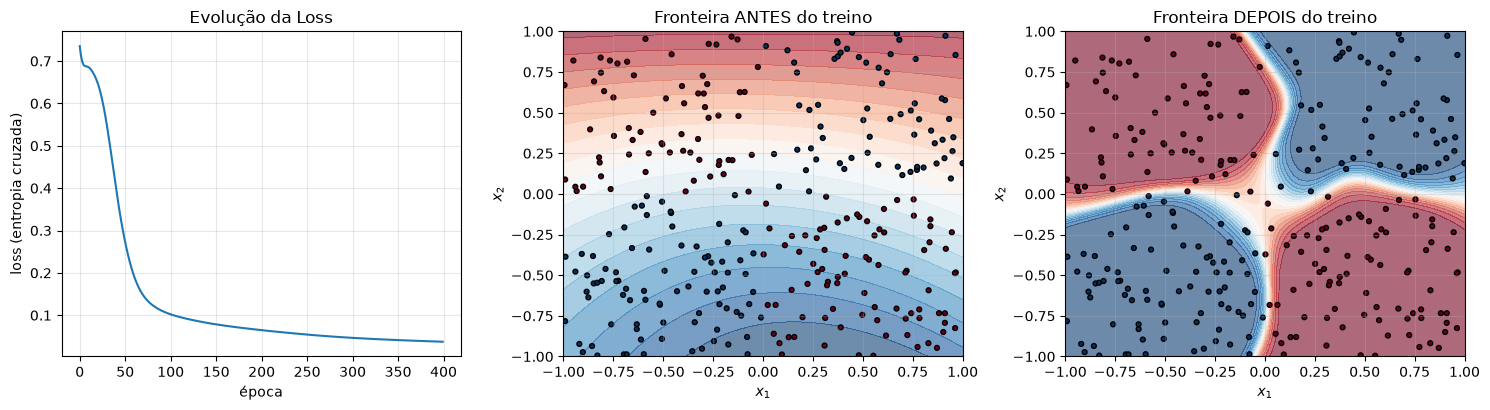

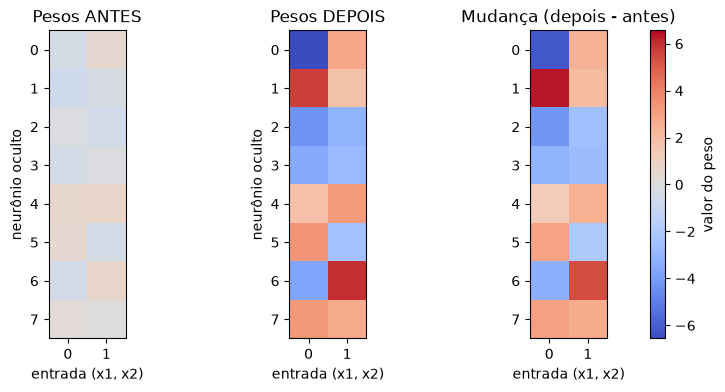

In [15]:
def fronteira(ax, modelo, titulo):
    g = torch.linspace(-1, 1, 120)
    gx, gy = torch.meshgrid(g, g, indexing="xy")
    with torch.no_grad():
        prob = torch.sigmoid(modelo(torch.stack([gx.flatten(), gy.flatten()], 1))).reshape(120, 120)
    ax.contourf(gx, gy, prob, levels=20, cmap="RdBu", alpha=0.6)
    ax.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor[:, 0], cmap="RdBu", edgecolors="k", s=12)
    ax.set(title=titulo, xlabel="$x_1$", ylabel="$x_2$")


fig, eixos = plt.subplots(1, 3, figsize=(15, 4.2))
eixos[0].plot(historico_loss)
eixos[0].set(title="Evolução da Loss", xlabel="época", ylabel="loss (entropia cruzada)")
fronteira(eixos[1], modelo_inicial, "Fronteira ANTES do treino")
fronteira(eixos[2], modelo, "Fronteira DEPOIS do treino")
plt.tight_layout()
plt.show()

fig, eixos = plt.subplots(1, 3, figsize=(11, 4))
limite = max(pesos_antes.abs().max(), pesos_depois.abs().max()).item()
for ax, w_, titulo in [(eixos[0], pesos_antes, "Pesos ANTES"), (eixos[1], pesos_depois, "Pesos DEPOIS")]:
    im = ax.imshow(w_, cmap="coolwarm", vmin=-limite, vmax=limite)
    ax.set(title=titulo, xlabel="entrada (x1, x2)", ylabel="neurônio oculto", xticks=[0, 1])
    ax.grid(False)
delta = pesos_depois - pesos_antes
im2 = eixos[2].imshow(delta, cmap="coolwarm", vmin=-limite, vmax=limite)
eixos[2].set(title="Mudança (depois - antes)", xlabel="entrada (x1, x2)", xticks=[0, 1])
eixos[2].grid(False)
fig.colorbar(im2, ax=eixos, label="valor do peso")
plt.show()

**Interpretação.** Três coisas aconteceram juntas. A **loss despencou** nas primeiras épocas e depois estabilizou. A **fronteira de decisão** passou de uma divisão arbitrária para os quatro quadrantes do XOR. E os **pesos mudaram**, como mostra o mapa da direita. Aprender é isso: deslocar números até que o conjunto resolva o problema.

Em LLMs reais, a mecânica é a mesma, com a loss calculada sobre a *próxima palavra*, bilhões de pesos e gradientes obtidos em lotes de texto por milhares de GPUs.

# 5. Armazenamento do aprendizado

Depois do treino, o que a rede aprendeu está apenas nos **pesos**, já que o código da arquitetura não muda. Eles ficam em **tensores** (arrays com formato e tipo numérico), organizados no `state_dict` do PyTorch. Vamos inspecioná-lo.

In [16]:
print(f"{'nome':12}{'formato':>12}{'dtype':>16}{'parâmetros':>12}")
for nome, tensor in modelo.state_dict().items():
    print(f"{nome:12}{str(tuple(tensor.shape)):>12}{str(tensor.dtype):>16}{tensor.numel():>12}")

total = sum(p.numel() for p in modelo.parameters())
print(f"\nTotal de parâmetros: {total}  (2*8 + 8 + 8*1 + 1)")
print("Primeira linha de pesos da camada 0:", modelo.state_dict()["0.weight"][0].numpy().round(3))

nome             formato           dtype  parâmetros
0.weight          (8, 2)   torch.float32          16
0.bias              (8,)   torch.float32           8
2.weight          (1, 8)   torch.float32           8
2.bias              (1,)   torch.float32           1

Total de parâmetros: 33  (2*8 + 8 + 8*1 + 1)
Primeira linha de pesos da camada 0: [-6.561  2.744]


**Interpretação.** Nossa rede tem só 33 parâmetros: uma matriz de pesos e um vetor de vieses por camada `Linear`. Os LLMs têm a mesma estrutura, com bilhões de números.

Para reutilizar o modelo, `torch.save` grava o `state_dict`, e uma rede nova com a mesma arquitetura o carrega. Um **checkpoint** guarda também o otimizador e a época, para retomar um treino interrompido. Usamos uma pasta temporária, então nada fica no projeto.

In [17]:
pasta = tempfile.mkdtemp()
caminho_pesos = os.path.join(pasta, "modelo_xor.pt")
caminho_ckpt = os.path.join(pasta, "checkpoint_xor.pt")

# 1) Só os pesos: o suficiente para inferência
torch.save(modelo.state_dict(), caminho_pesos)

modelo_novo = nn.Sequential(nn.Linear(2, 8), nn.Tanh(), nn.Linear(8, 1))
print("Acurácia do modelo novo (pesos aleatórios):", f"{acuracia(modelo_novo, X_xor, y_xor):.1%}")
modelo_novo.load_state_dict(torch.load(caminho_pesos, weights_only=True))
print("Acurácia após carregar os pesos salvos:   ", f"{acuracia(modelo_novo, X_xor, y_xor):.1%}")

with torch.no_grad():
    iguais = torch.allclose(modelo(X_xor), modelo_novo(X_xor))
print("Saídas idênticas ao modelo original:", iguais)

# 2) Checkpoint: pesos + otimizador + progresso, para retomar o treino
torch.save({"epoca": 400, "modelo": modelo.state_dict(),
            "otimizador": otimizador.state_dict(), "loss": historico_loss[-1]}, caminho_ckpt)
ckpt = torch.load(caminho_ckpt, weights_only=True)
print(f"\nCheckpoint contém: {list(ckpt)} | época {ckpt['epoca']} | loss {ckpt['loss']:.4f}")
print(f"Tamanho em disco: pesos = {os.path.getsize(caminho_pesos)} bytes | "
      f"checkpoint = {os.path.getsize(caminho_ckpt)} bytes")

Acurácia do modelo novo (pesos aleatórios): 42.7%
Acurácia após carregar os pesos salvos:    99.3%
Saídas idênticas ao modelo original: True

Checkpoint contém: ['epoca', 'modelo', 'otimizador', 'loss'] | época 400 | loss 0.0375
Tamanho em disco: pesos = 2555 bytes | checkpoint = 6093 bytes


**Interpretação.** O modelo novo acertava ao acaso e, depois de `load_state_dict`, reproduz exatamente o original: o aprendizado foi transferido só copiando números. O checkpoint é maior porque inclui o estado do Adam (duas médias por peso). Em treinos reais, chega a cerca do triplo do tamanho do modelo.

Existem, portanto, duas formas de salvar. Só os **pesos** bastam para a *inferência*, e é o que se distribui. O **estado completo** (pesos, otimizador e época) serve para *retomar o treinamento* de onde ele parou. Vamos retomar o nosso de duas maneiras: com o checkpoint completo e só com os pesos.

In [18]:
def retomar(com_estado_do_otimizador, epocas=30):
    m = nn.Sequential(nn.Linear(2, 8), nn.Tanh(), nn.Linear(8, 1))
    m.load_state_dict(ckpt["modelo"])                      # pesos em uma nova instância
    otim = torch.optim.Adam(m.parameters(), lr=0.03)
    if com_estado_do_otimizador:
        otim.load_state_dict(ckpt["otimizador"])           # médias internas do Adam
    perdas = []
    for _ in range(epocas):
        perda = F.binary_cross_entropy_with_logits(m(X_xor), y_xor)
        otim.zero_grad()
        perda.backward()
        otim.step()
        perdas.append(perda.item())
    return perdas


print(f"Loss salva no checkpoint (época {ckpt['epoca']}): {ckpt['loss']:.4f}\n")
print(f"{'retomada':26}{'época +1':>10}{'+2':>9}{'+5':>9}{'+30':>9}")
for nome, completo in [("checkpoint completo", True), ("só os pesos", False)]:
    p = retomar(completo)
    print(f"{nome:26}{p[0]:10.4f}{p[1]:9.4f}{p[4]:9.4f}{p[-1]:9.4f}")

Loss salva no checkpoint (época 400): 0.0375

retomada                    época +1       +2       +5      +30
checkpoint completo           0.0374   0.0374   0.0372   0.0356
só os pesos                   0.0374   0.0372   0.0365   0.0311


**Interpretação.** Os dois caminhos retomam de onde o treino parou: a loss começa em 0,0374, praticamente a do checkpoint (0,0375). A diferença está na trajetória. Com o checkpoint completo, o Adam continua com suas médias internas e mantém o ritmo anterior. Só com os pesos, ele recomeça "do zero" e dá passos maiores no início, o que aqui até reduziu a loss mais rápido (0,0311 contra 0,0356 após 30 épocas). Não há um vencedor geral: o checkpoint completo garante uma continuação fiel, e os pesos bastam para começar uma nova etapa, como um fine-tuning.

O tamanho em memória é `parâmetros × bytes por número`, e a precisão numérica pesa muito:

In [19]:
bytes_por_tipo = {"float32": 4, "float16": 2, "int8": 1, "int4": 0.5}
modelos_ref = {"GPT-2 small": 124e6, "Modelo 7B": 7e9, "Modelo 70B": 70e9}

print(f"{'modelo':14}" + "".join(f"{t:>10}" for t in bytes_por_tipo))
for nome, n in modelos_ref.items():
    print(f"{nome:14}" + "".join(f"{n * b / 1e9:>9.1f}G" for b in bytes_por_tipo.values()))

modelo           float32   float16      int8      int4
GPT-2 small         0.5G      0.2G      0.1G      0.1G
Modelo 7B          28.0G     14.0G      7.0G      3.5G
Modelo 70B        280.0G    140.0G     70.0G     35.0G


**Interpretação.** Um modelo de 7 bilhões de parâmetros ocupa cerca de 28 GB em `float32`, 14 GB em `float16` e menos de 4 GB com 4 bits. A precisão decide se ele roda num servidor, numa GPU comum ou num celular. Voltaremos a isso no capítulo 10.

# 6. Fine-tuning

Treinar um LLM do zero custa milhões de dólares, e felizmente não precisamos repetir isso a cada tarefa. O caminho usual é **pré-treinar** o modelo em texto geral, reaproveitar seus pesos em outra tarefa (**Transfer Learning**) e ensiná-lo a seguir instruções com exemplos *instrução → resposta* (**SFT**). Quando os recursos são curtos, ajusta-se apenas uma pequena fração dos pesos (**PEFT**), e o **LoRA** é a técnica mais popular.

Vamos ver a transferência em escala de brinquedo. Uma rede aprende $y = \sin(x)$ com muitos pontos (o pré-treino). Depois queremos $y = \sin(x) + 0{,}4x$, mas só com **8 exemplos**. Compararemos treinar do zero, ajustar tudo e usar LoRA.

In [20]:
def criar_mlp():
    return nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1))


def treinar(modelo, x, y, passos, lr):
    otim = torch.optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=lr)
    historico = []
    for _ in range(passos):
        perda = F.mse_loss(modelo(x), y)
        otim.zero_grad()
        perda.backward()
        otim.step()
        historico.append(perda.item())
    return historico


def contar(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


# Pré-treino com muitos dados
torch.manual_seed(SEMENTE)
x_grade = torch.linspace(-3, 3, 200).unsqueeze(1)
pre_treinado = criar_mlp()
treinar(pre_treinado, x_grade, torch.sin(x_grade), passos=1500, lr=0.01)

# Tarefa nova: poucos exemplos
x_few = torch.empty(8, 1).uniform_(-3, 3)
y_few = torch.sin(x_few) + 0.4 * x_few
y_verdade = torch.sin(x_grade) + 0.4 * x_grade

def erro_teste(m):
    with torch.no_grad():
        return F.mse_loss(m(x_grade), y_verdade).item()

print(f"Erro (MSE) do modelo pré-treinado SEM ajuste na tarefa nova: {erro_teste(pre_treinado):.4f}")

Erro (MSE) do modelo pré-treinado SEM ajuste na tarefa nova: 0.4846


## LoRA: ajustar sem mexer nos pesos originais

O LoRA **congela** a matriz $W$ e soma a ela uma correção de baixo posto:

$$ W' = W + \frac{\alpha}{r}\, B A, \qquad A \in \mathbb{R}^{r \times d_{in}},\; B \in \mathbb{R}^{d_{out} \times r} $$

Com $r$ pequeno, $A$ e $B$ têm muito menos números que $W$, e só eles são treinados. Como $B$ começa zerada, o modelo parte **exatamente** do original.

Antes de treinar, LoRA == original? True



método                parâmetros treinados   erro no teste (MSE)
sem ajuste                               0                0.4846
do zero                               1153                0.0099
full fine-tuning                      1153                0.0004
LoRA (r=2)                             260                0.0007


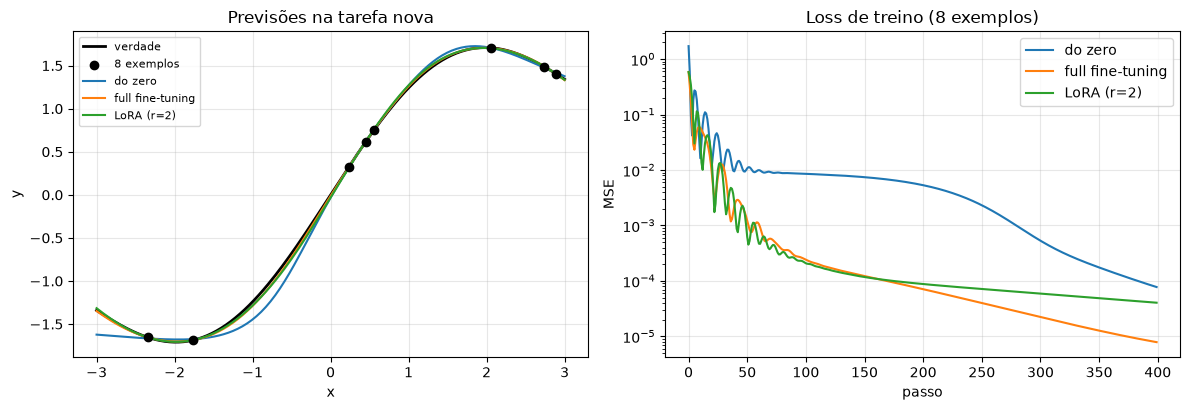

In [21]:
class LoRALinear(nn.Module):
    def __init__(self, base, r=2, alpha=4):
        super().__init__()
        self.base = base
        self.A = nn.Parameter(torch.randn(r, base.in_features) * 0.1)
        self.B = nn.Parameter(torch.zeros(base.out_features, r))  # zero: começa igual ao original
        self.escala = alpha / r

    def forward(self, x):
        return self.base(x) + (x @ self.A.T @ self.B.T) * self.escala


def aplicar_lora(modelo, r=2):
    for p in modelo.parameters():
        p.requires_grad = False  # congela tudo
    for i, camada in enumerate(modelo):
        if isinstance(camada, nn.Linear):
            modelo[i] = LoRALinear(camada, r)  # A e B são novos e treináveis
    return modelo


torch.manual_seed(SEMENTE)
com_lora = aplicar_lora(deepcopy(pre_treinado))
with torch.no_grad():
    print("Antes de treinar, LoRA == original?",
          torch.allclose(com_lora(x_grade), pre_treinado(x_grade)))

passos = 400
modelos = {
    "do zero": criar_mlp(),
    "full fine-tuning": deepcopy(pre_treinado),
    "LoRA (r=2)": com_lora,
}
lrs = {"do zero": 0.01, "full fine-tuning": 0.003, "LoRA (r=2)": 0.01}
curvas = {nome: treinar(m, x_few, y_few, passos, lrs[nome]) for nome, m in modelos.items()}

print(f"\n{'método':20}{'parâmetros treinados':>22}{'erro no teste (MSE)':>22}")
print(f"{'sem ajuste':20}{0:>22}{erro_teste(pre_treinado):>22.4f}")
for nome, m in modelos.items():
    print(f"{nome:20}{contar(m):>22}{erro_teste(m):>22.4f}")

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2))
eixos[0].plot(x_grade, y_verdade, "k", lw=2, label="verdade")
eixos[0].scatter(x_few, y_few, c="k", zorder=5, label="8 exemplos")
for nome, m in modelos.items():
    with torch.no_grad():
        eixos[0].plot(x_grade, m(x_grade), label=nome)
eixos[0].set(title="Previsões na tarefa nova", xlabel="x", ylabel="y")
eixos[0].legend(fontsize=8)
for nome, c in curvas.items():
    eixos[1].plot(c, label=nome)
eixos[1].set(title="Loss de treino (8 exemplos)", xlabel="passo", ylabel="MSE", yscale="log")
eixos[1].legend()
plt.tight_layout()
plt.show()

**Interpretação.** Os métodos que partem do modelo pré-treinado já "conhecem" a forma da curva, enquanto o modelo treinado do zero, com só 8 pontos, erra mais nas bordas. O LoRA treinou 260 parâmetros contra 1.153 do ajuste completo (pouco mais de um quinto) e ficou perto dele em erro. Em modelos de bilhões de parâmetros, essa diferença torna o fine-tuning viável numa única GPU.

É um experimento minúsculo, com uma única semente, então o ganho exato varia. O que se mantém é a ideia: reaproveitar o que já foi aprendido e treinar pouco.

No **SFT**, o treino continua sendo prever o próximo token, mas a loss é calculada **só nos tokens da resposta**. Os do prompt servem de contexto.

In [22]:
exemplo_sft = {
    "instrucao": "Resuma em uma frase: o Transformer usa atenção para relacionar palavras.",
    "resposta": "O Transformer relaciona palavras usando atenção.",
}
print(exemplo_sft, "\n")

# Demonstração da máscara de loss com tokens fictícios (vocabulário de 10 IDs)
torch.manual_seed(SEMENTE)
logits = torch.randn(7, 10)                                  # 7 posições, 10 IDs possíveis
alvos = torch.tensor([-100, -100, -100, -100, 3, 5, 8])      # 4 de prompt (ignorados) + 3 de resposta
perda_sft = F.cross_entropy(logits, alvos, ignore_index=-100)
perda_so_resposta = F.cross_entropy(logits[4:], alvos[4:])
print(f"Loss com máscara (-100 nos tokens do prompt): {perda_sft.item():.4f}")
print(f"Loss calculada só nas posições da resposta:   {perda_so_resposta.item():.4f}")

{'instrucao': 'Resuma em uma frase: o Transformer usa atenção para relacionar palavras.', 'resposta': 'O Transformer relaciona palavras usando atenção.'} 

Loss com máscara (-100 nos tokens do prompt): 2.8390
Loss calculada só nas posições da resposta:   2.8390


**Interpretação.** O valor `-100` faz o PyTorch ignorar a posição, e as duas perdas saem iguais.

Na prática, o LoRA é aplicado por bibliotecas como a `peft`, sobre modelos da Hugging Face. O trecho abaixo não é executado aqui, pois exige baixar um modelo:

```python
from peft import LoraConfig, get_peft_model

config = LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")
modelo = get_peft_model(modelo_base, config)
modelo.print_trainable_parameters()   # tipicamente menos de 1% dos parâmetros
```

O resultado é um arquivo pequeno, só com as matrizes $A$ e $B$ (alguns megabytes). Um mesmo modelo base pode ter vários adaptadores, um por tarefa.

## Fine-tuning de ponta a ponta

Vamos juntar tudo com um modelo já pronto: a rede do capítulo 4, **pré-treinada** no XOR clássico. Queremos *especializá-la* numa variante em que as fronteiras estão deslocadas, e só temos **40 exemplos**. O roteiro é avaliar, ajustar, comparar, salvar, carregar e usar.

| Fase | O que acontece com os pesos |
|---|---|
| Treinamento do zero (cap. 4) | partem aleatórios e são aprendidos com muitos dados |
| Fine-tuning | partem de um modelo pronto e são ajustados com poucos dados |
| Inferência | ficam fixos, e só se calcula a saída |

In [23]:
def tarefa_especifica(n):
    X = torch.rand(n, 2) * 2 - 1
    y = (((X[:, 0] - 0.4) * (X[:, 1] + 0.4)) > 0).float().unsqueeze(1)  # XOR com o centro deslocado
    return X, y


torch.manual_seed(SEMENTE + 1)
X_esp, y_esp = tarefa_especifica(40)               # dataset pequeno de especialização
X_esp_teste, y_esp_teste = tarefa_especifica(500)  # dados novos, para avaliar

base = deepcopy(modelo)  # modelo pré-treinado do capítulo 4, que continua intacto

with torch.no_grad():
    perda_antes = F.binary_cross_entropy_with_logits(base(X_esp_teste), y_esp_teste).item()
print("ANTES do fine-tuning (modelo pré-treinado na tarefa nova)")
print(f"  acurácia: {acuracia(base, X_esp_teste, y_esp_teste):.1%} | loss: {perda_antes:.3f}")

ANTES do fine-tuning (modelo pré-treinado na tarefa nova)
  acurácia: 69.4% | loss: 1.610


modelo                        tarefa nova  XOR original
pré-treinado (antes)                69.4%         99.3%
fine-tuning (depois)                85.8%         79.0%
do zero, mesmo orçamento            72.6%         69.3%


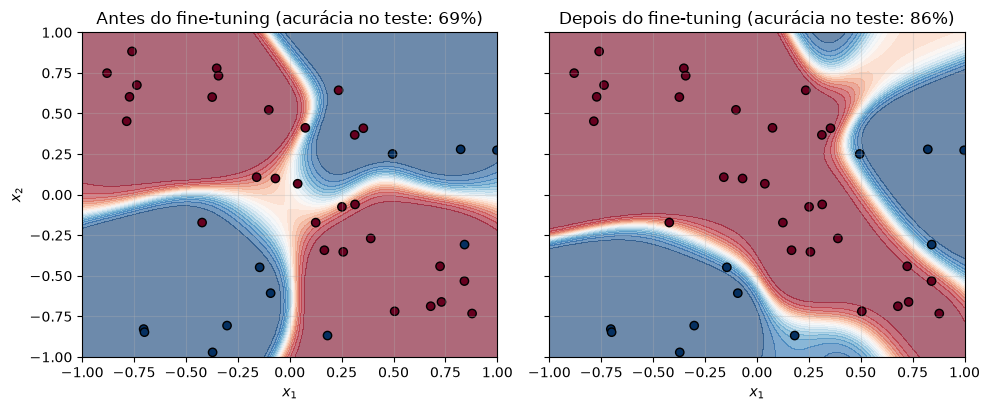

In [24]:
ajustado = deepcopy(base)
otim = torch.optim.Adam(ajustado.parameters(), lr=0.01)
perdas_ft = []
for _ in range(150):  # poucos passos e taxa baixa: só um ajuste fino
    perda = F.binary_cross_entropy_with_logits(ajustado(X_esp), y_esp)
    otim.zero_grad()
    perda.backward()
    otim.step()
    perdas_ft.append(perda.item())

# Referência: mesma tarefa, mesmos 40 exemplos e mesmo orçamento, mas partindo de pesos aleatórios
torch.manual_seed(SEMENTE)
do_zero = nn.Sequential(nn.Linear(2, 8), nn.Tanh(), nn.Linear(8, 1))
otim = torch.optim.Adam(do_zero.parameters(), lr=0.01)
for _ in range(150):
    perda = F.binary_cross_entropy_with_logits(do_zero(X_esp), y_esp)
    otim.zero_grad()
    perda.backward()
    otim.step()

print(f"{'modelo':28}{'tarefa nova':>13}{'XOR original':>14}")
for nome, m in [("pré-treinado (antes)", base), ("fine-tuning (depois)", ajustado), ("do zero, mesmo orçamento", do_zero)]:
    print(f"{nome:28}{acuracia(m, X_esp_teste, y_esp_teste):13.1%}{acuracia(m, X_xor, y_xor):14.1%}")

grade = torch.linspace(-1, 1, 100)
gx, gy = torch.meshgrid(grade, grade, indexing="xy")
pontos_grade = torch.stack([gx.flatten(), gy.flatten()], dim=1)
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, m, titulo in [(eixos[0], base, "Antes do fine-tuning"), (eixos[1], ajustado, "Depois do fine-tuning")]:
    with torch.no_grad():
        prob = torch.sigmoid(m(pontos_grade)).reshape(100, 100)
    ax.contourf(gx, gy, prob, levels=20, cmap="RdBu", alpha=0.6)
    ax.scatter(X_esp[:, 0], X_esp[:, 1], c=y_esp[:, 0], cmap="RdBu", edgecolors="k")
    ax.set(title=f"{titulo} (acurácia no teste: {acuracia(m, X_esp_teste, y_esp_teste):.0%})", xlabel="$x_1$")
eixos[0].set_ylabel("$x_2$")
plt.tight_layout()
plt.show()

**Interpretação.** Antes, o modelo pré-treinado acertava 69% na tarefa nova, porque seus quadrantes estavam no lugar errado. Depois de 150 passos de ajuste com 40 exemplos, a acurácia subiu para 86%, e o gráfico mostra a fronteira deslocada para acompanhar os novos dados. O modelo treinado do zero, com o mesmo orçamento, chegou a 73%: partir de um modelo pronto ajudou (com uma única semente, então os valores exatos variam).

Há um preço. A acurácia no XOR original caiu de 99% para 79%, porque os mesmos pesos passaram a servir à tarefa nova. É o *esquecimento catastrófico*, um dos motivos para técnicas como o LoRA, que preservam os pesos originais.

Falta guardar o resultado. Salvamos só os pesos especializados, criamos uma instância nova e a usamos em previsões novas.

In [25]:
caminho_especializado = os.path.join(pasta, "modelo_especializado.pt")
torch.save(ajustado.state_dict(), caminho_especializado)

recarregado = nn.Sequential(nn.Linear(2, 8), nn.Tanh(), nn.Linear(8, 1))  # instância nova, pesos aleatórios
recarregado.load_state_dict(torch.load(caminho_especializado, weights_only=True))

with torch.no_grad():
    iguais = torch.allclose(ajustado(X_esp_teste), recarregado(X_esp_teste))
print("Saídas idênticas antes e depois de recarregar:", iguais)
print(f"Acurácia do modelo recarregado: {acuracia(recarregado, X_esp_teste, y_esp_teste):.1%} "
      f"(o ajustado tinha {acuracia(ajustado, X_esp_teste, y_esp_teste):.1%})\n")

# Inferência: pontos novos, escolhidos onde as duas tarefas discordam
novos = torch.tensor([[0.2, -0.8], [0.2, 0.2], [0.8, -0.2], [-0.8, 0.8]])
verdade = (((novos[:, 0] - 0.4) * (novos[:, 1] + 0.4)) > 0).int()
with torch.no_grad():
    p_base = torch.sigmoid(base(novos))[:, 0]
    p_novo = torch.sigmoid(recarregado(novos))[:, 0]

print(f"{'ponto (x1, x2)':>16}{'correto':>9}{'P(base)':>10}{'P(recarregado)':>16}")
for (x1, x2), v, pb, pn in zip(novos.tolist(), verdade.tolist(), p_base.tolist(), p_novo.tolist()):
    print(f"{f'({x1:.1f}, {x2:.1f})':>16}{v:9d}{pb:10.2f}{pn:16.2f}")

Saídas idênticas antes e depois de recarregar: True
Acurácia do modelo recarregado: 85.8% (o ajustado tinha 85.8%)

  ponto (x1, x2)  correto   P(base)  P(recarregado)
     (0.2, -0.8)        1      0.00            0.58
      (0.2, 0.2)        0      0.98            0.01
     (0.8, -0.2)        1      0.00            0.96
     (-0.8, 0.8)        0      0.00            0.00


**Interpretação.** As saídas do modelo recarregado são idênticas às do ajustado (`True`) e a acurácia é a mesma (85,8%): o aprendizado está inteiro nos pesos salvos.

Na inferência, os pesos ficam fixos. Nos quatro pontos novos, o modelo base do capítulo 4 erra três (probabilidades 0,00, 0,98 e 0,00, onde o certo era 1, 0 e 1), e o recarregado acerta os quatro. No primeiro ponto, porém, a confiança é baixa (0,58), sinal de incerteza com apenas 40 exemplos.

# 7. Inferência

**Inferência** é rodar só o forward pass, sem gradientes nem atualização de pesos. Um modelo de linguagem não escreve a resposta de uma vez. Ele repete um laço: recebe o contexto, produz uma pontuação (**logit**) para cada token, converte as pontuações em probabilidades com a **softmax**, sorteia um token e o adiciona ao contexto.

Para ver isso do início ao fim, treinamos um modelo de linguagem minúsculo, que prevê o próximo *caractere* a partir dos 6 anteriores.

> **Simplificação:** usamos caracteres no lugar de subpalavras, um corpus sintético de frases simples (gerado por uma pequena gramática) e uma MLP no lugar de um Transformer. O laço de geração é o mesmo dos LLMs reais.

o sistema ajusta os pesos a cada passo. a inteligência artificial ajusta os padrões a cada passo. o sistema guarda o erro com atenção. a inteligência artificial calcula a próxima palavra com atenção.  ...
6610 caracteres | vocabulário: 26 símbolos | treino: 5612 exemplos | validação: 992
Exemplo: 'o sist' -> 'e'


Perda inicial (chute uniforme): 3.258
Perda final: treino 0.141 | validação 0.211


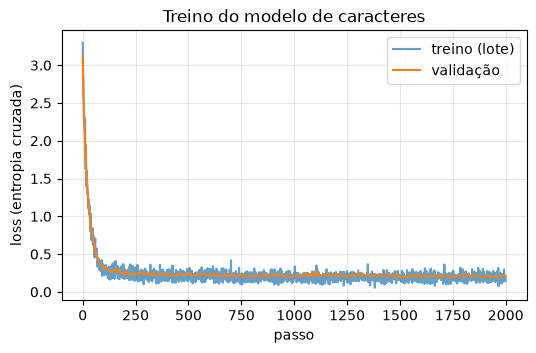

In [26]:
import random

sorteio = random.Random(0)
sujeitos = ["o modelo", "a rede", "o texto", "o sistema", "a inteligência artificial"]
verbos = ["aprende", "calcula", "guarda", "ajusta", "prevê", "lê"]
objetos = ["os pesos", "o contexto", "a próxima palavra", "os padrões", "o erro", "a atenção", "os exemplos"]
finais = ["", " com atenção", " a cada passo", " em cada camada", " durante o treino"]
frases = [f"{sorteio.choice(sujeitos)} {sorteio.choice(verbos)} {sorteio.choice(objetos)}{sorteio.choice(finais)}."
          for _ in range(160)]
texto = " ".join(frases)
print(texto[:200], "...")

caracteres = sorted(set(texto))
c2i = {c: i for i, c in enumerate(caracteres)}
i2c = {i: c for c, i in c2i.items()}
CTX = 6


def montar_exemplos(trecho):
    ids = [c2i[c] for c in trecho]
    X = torch.tensor([ids[i:i + CTX] for i in range(len(ids) - CTX)])
    y = torch.tensor([ids[i + CTX] for i in range(len(ids) - CTX)])
    return X, y


corte = int(len(texto) * 0.85)  # validação: as últimas frases, que o modelo não vê no treino
X_tr, y_tr = montar_exemplos(texto[:corte])
X_va, y_va = montar_exemplos(texto[corte - CTX:])
print(f"{len(texto)} caracteres | vocabulário: {len(caracteres)} símbolos | "
      f"treino: {len(X_tr)} exemplos | validação: {len(X_va)}")
print("Exemplo:", repr(texto[:CTX]), "->", repr(texto[CTX]))


class ModeloCaracteres(nn.Module):
    def __init__(self, tam_vocab, contexto, dim_emb=16, oculto=128):
        super().__init__()
        self.emb = nn.Embedding(tam_vocab, dim_emb)
        self.mlp = nn.Sequential(nn.Linear(contexto * dim_emb, oculto), nn.Tanh(), nn.Linear(oculto, tam_vocab))

    def forward(self, x):
        return self.mlp(self.emb(x).flatten(1))  # logits: um por caractere do vocabulário


def perda_media(modelo, X, y):
    with torch.no_grad():
        return F.cross_entropy(modelo(X), y).item()


torch.manual_seed(SEMENTE)
lm = ModeloCaracteres(len(caracteres), CTX)
otim = torch.optim.Adam(lm.parameters(), lr=0.005)
curva_tr, curva_va = [], []
for passo in range(2000):
    lote = torch.randint(0, len(X_tr), (128,))
    perda = F.cross_entropy(lm(X_tr[lote]), y_tr[lote])
    otim.zero_grad()
    perda.backward()
    otim.step()
    curva_tr.append(perda.item())
    curva_va.append(perda_media(lm, X_va, y_va))

print(f"Perda inicial (chute uniforme): {math.log(len(caracteres)):.3f}")
print(f"Perda final: treino {curva_tr[-1]:.3f} | validação {curva_va[-1]:.3f}")
plt.figure(figsize=(6, 3.5))
plt.plot(curva_tr, label="treino (lote)", alpha=0.7)
plt.plot(curva_va, label="validação")
plt.title("Treino do modelo de caracteres")
plt.xlabel("passo")
plt.ylabel("loss (entropia cruzada)")
plt.legend()
plt.show()

**Interpretação.** Partimos de $\ln(\text{vocabulário})$, o erro de quem chuta qualquer caractere, e a loss de treino cai de cerca de 3,3 para perto de 0,14. A loss de **validação**, medida em frases que o modelo não viu, fica um pouco acima (cerca de 0,21): ele aprendeu a estrutura das frases, mas já começa a decorar detalhes. Uma lacuna grande entre as curvas seria o sinal clássico de *overfitting*, tema do capítulo 10.

Para um dado contexto, o modelo devolve logits, e a softmax os converte em probabilidades. Veja a distribuição para `"o modelo "` com três temperaturas.

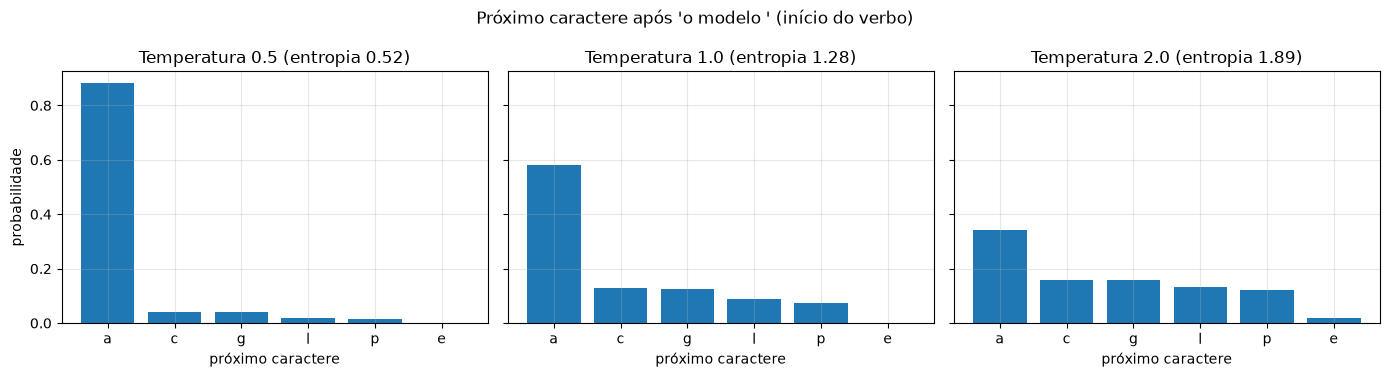

In [27]:
def rotulo(c):
    return "␣" if c == " " else c


def distribuicao(modelo, contexto, temperatura=1.0):
    ids = [c2i.get(c, c2i[" "]) for c in contexto]
    ids = ([c2i[" "]] * CTX + ids)[-CTX:]
    with torch.no_grad():
        logits = modelo(torch.tensor([ids]))[0]
    return F.softmax(logits / temperatura, dim=-1)


contexto = "o modelo "
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, T in zip(eixos, [0.5, 1.0, 2.0]):
    p = distribuicao(lm, contexto, T)
    top = p.topk(6)
    ax.bar([rotulo(i2c[i.item()]) for i in top.indices], top.values)
    entropia = -(p * torch.log(p + 1e-12)).sum().item()
    ax.set(title=f"Temperatura {T} (entropia {entropia:.2f})", xlabel="próximo caractere")
eixos[0].set_ylabel("probabilidade")
plt.suptitle(f"Próximo caractere após {contexto!r} (início do verbo)")
plt.tight_layout()
plt.show()

**Interpretação.** A **temperatura** divide os logits antes da softmax. Com valor baixo (0,5), a distribuição fica afiada e o texto, previsível. Com valor alto (2,0), ela achata e caracteres improváveis ganham chance. A entropia, que mede a incerteza, sobe junto. A temperatura não muda o modelo, só a forma de sortear a partir dele.

Agora o laço completo de geração. Além da temperatura, o **top-k** deixa concorrer apenas os $k$ caracteres mais prováveis, e `temperatura=0` escolhe sempre o mais provável (decodificação gananciosa).

In [28]:
@torch.no_grad()
def gerar(modelo, prompt, n=110, temperatura=1.0, top_k=None, semente=0):
    gerador = torch.Generator().manual_seed(semente)
    ids = [c2i.get(c, c2i[" "]) for c in prompt]
    for _ in range(n):
        contexto_ids = ([c2i[" "]] * CTX + ids)[-CTX:]
        logits = modelo(torch.tensor([contexto_ids]))[0]
        if temperatura == 0:
            proximo = int(logits.argmax())
        else:
            logits = logits / temperatura
            if top_k:
                logits = logits.masked_fill(logits < logits.topk(top_k).values[-1], float("-inf"))
            proximo = int(torch.multinomial(F.softmax(logits, dim=-1), 1, generator=gerador))
        ids.append(proximo)
    return "".join(i2c[i] for i in ids)


prompt = "o texto "
for T, k in [(0, None), (0.5, None), (1.0, None), (1.5, None), (1.5, 3)]:
    print(f"temperatura={T}, top_k={k}")
    print("  ", gerar(lm, prompt, temperatura=T, top_k=k), "\n")

temperatura=0, top_k=None
   o texto aprende os exemplos com atenção. o sistema aprende os exemplos com atenção. o sistema aprende os exemplos com  

temperatura=0.5, top_k=None
   o texto aprende os exemplos durante o treino. o sistema aprende os pesos durante o treino. a rede guarda o erro durant 

temperatura=1.0, top_k=None
   o texto aprende os exemplos. a rede aprende a próxima palavra em cada camada. o modelo lê o erro a cada camada. a rede 

temperatura=1.5, top_k=None
   o texto aprende os exemplos. a rede aprende a próxima palavra em cada camada. o modelo lê o erro a cadcucama al ajrsis 

temperatura=1.5, top_k=3
   o texto aprende os exemplos. a rede aprende a próxima palavra em cada camada. o modelo guarda a próxima palavra a cada 



**Interpretação.** Com `temperatura=0`, o resultado é determinístico e repete estruturas aprendidas. Em 1,0, surgem frases novas e variadas. Em 1,5, aparecem palavras "inventadas" (como "cadcucama"). O **top-k** descarta as escolhas mais improváveis e, na última linha, o texto permaneceu coerente (os resultados mudam com a semente).

Num LLM real, o laço *contexto → logits → softmax → sorteio* é o mesmo. A diferença está na escala: milhares de tokens de contexto, atenção no lugar de uma janela fixa e trilhões de tokens de treino.

# 8. Generative AI

Um LLM gera texto condicionado ao **contexto**, o *prompt*. Mudar o prompt muda as probabilidades, e essa é a base do *Prompt Engineering*: escolher o contexto que leva o modelo ao comportamento desejado, **sem alterar nenhum peso**.

Com nosso modelo de caracteres, dois contextos diferentes já produzem previsões diferentes.

In [29]:
for contexto in ["o modelo ", "a rede lê os pesos "]:
    p = distribuicao(lm, contexto)
    top = p.topk(3)
    itens = ", ".join(f"{rotulo(i2c[i.item()])!r}: {v:.0%}" for v, i in zip(top.values, top.indices))
    print(f"...{contexto[-CTX:]!r:10} -> {itens}")

...'odelo '   -> 'a': 58%, 'c': 13%, 'g': 13%
...'pesos '   -> 'a': 43%, 'd': 30%, 'c': 17%


**Interpretação.** Depois de "modelo " vem o início de um verbo, e depois de "pesos " vem o início de um complemento (com, a cada, durante...). Cada contexto empurrou as probabilidades para um lado. Num LLM real o princípio é o mesmo, mas o contexto é o prompt inteiro.

Há três formas comuns de pedir algo. No **zero-shot**, o prompt traz só a instrução, o que basta para tarefas simples. No **few-shot**, ele inclui exemplos resolvidos, úteis quando o formato precisa ser mostrado. Nos modelos de chat, as mensagens têm papéis (`system` e `user`). Os exemplos do prompt agem como um treino temporário, que vive só no contexto: é o ***in-context learning***. Veja os três formatos:

In [30]:
zero_shot = "Classifique o sentimento da frase como POSITIVO ou NEGATIVO.\nFrase: O curso foi excelente.\nSentimento:"

few_shot = """Classifique o sentimento da frase como POSITIVO ou NEGATIVO.

Frase: Adorei a aula de hoje.
Sentimento: POSITIVO

Frase: O material estava confuso.
Sentimento: NEGATIVO

Frase: O curso foi excelente.
Sentimento:"""

mensagens_chat = [
    {"role": "system", "content": "Você é um tutor de IA. Responda em português, em no máximo duas frases."},
    {"role": "user", "content": "O que é um embedding?"},
]

print("--- ZERO-SHOT ---\n" + zero_shot)
print("\n--- FEW-SHOT ---\n" + few_shot)
print("\n--- CHAT (system + user) ---")
for m in mensagens_chat:
    print(f"[{m['role']}] {m['content']}")

--- ZERO-SHOT ---
Classifique o sentimento da frase como POSITIVO ou NEGATIVO.
Frase: O curso foi excelente.
Sentimento:

--- FEW-SHOT ---
Classifique o sentimento da frase como POSITIVO ou NEGATIVO.

Frase: Adorei a aula de hoje.
Sentimento: POSITIVO

Frase: O material estava confuso.
Sentimento: NEGATIVO

Frase: O curso foi excelente.
Sentimento:

--- CHAT (system + user) ---
[system] Você é um tutor de IA. Responda em português, em no máximo duas frases.
[user] O que é um embedding?


**Interpretação.** No few-shot, os dois exemplos mostram o formato exato da resposta, e o modelo tende a segui-lo. É a mesma ideia dos pipelines do notebook da FIAP, que passam `system` e `user` ao Qwen. Modelos de chat passaram por SFT (capítulo 6) para entender esses papéis. Sem isso, eles apenas continuam o texto recebido.

Um LLM só sabe o que viu no treino, o que envelhece ou não inclui seus documentos. O **RAG** (*Retrieval-Augmented Generation*) resolve isso: **recupera** os trechos mais parecidos com a pergunta, os **coloca no prompt** e deixa o LLM **gerar** a resposta com esse contexto. A busca compara vetores, como nos embeddings do capítulo 2. Aqui usamos contagem de palavras com peso TF-IDF no lugar de embeddings neurais, e paramos antes da geração.

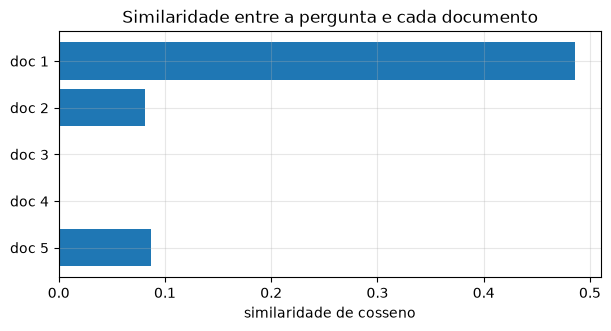

Responda usando apenas o contexto.

Contexto: LoRA ajusta um modelo grande treinando poucas matrizes pequenas, o que reduz o custo de memória.

Pergunta: como reduzir o custo de ajustar um modelo grande?
Resposta:


In [31]:
documentos = [
    "LoRA ajusta um modelo grande treinando poucas matrizes pequenas, o que reduz o custo de memória.",
    "A temperatura controla o quanto o modelo arrisca ao escolher o próximo token.",
    "Um checkpoint guarda os pesos e o estado do otimizador para retomar o treinamento.",
    "A tokenização divide o texto em tokens que são convertidos em números.",
    "A quantização reduz o tamanho do modelo usando números com menos bits.",
]
pergunta = "como reduzir o custo de ajustar um modelo grande?"
palavras_vazias = {"o", "a", "os", "as", "um", "uma", "de", "do", "da", "em", "que", "e", "para", "com", "como", "ao"}


def palavras_de(texto):
    return [p for p in re.findall(r"\w+", texto.lower()) if p not in palavras_vazias]


tokens_docs = [palavras_de(d) for d in documentos]
vocab_rag = sorted({p for t in tokens_docs for p in t})
idf = {p: math.log(len(documentos) / sum(p in t for t in tokens_docs)) + 1 for p in vocab_rag}


def vetor_tfidf(tokens):
    contagem = Counter(tokens)
    return torch.tensor([contagem[p] * idf[p] for p in vocab_rag])


matriz_docs = torch.stack([vetor_tfidf(t) for t in tokens_docs])
vetor_pergunta = vetor_tfidf(palavras_de(pergunta))
similaridades = F.cosine_similarity(matriz_docs, vetor_pergunta.unsqueeze(0), dim=1)

plt.figure(figsize=(7, 3.2))
plt.barh([f"doc {i + 1}" for i in range(len(documentos))], similaridades)
plt.gca().invert_yaxis()
plt.title("Similaridade entre a pergunta e cada documento")
plt.xlabel("similaridade de cosseno")
plt.show()

melhor = similaridades.argmax().item()
prompt_rag = (f"Responda usando apenas o contexto.\n\nContexto: {documentos[melhor]}\n\n"
              f"Pergunta: {pergunta}\nResposta:")
print(prompt_rag)

**Interpretação.** O documento 1, que explica o LoRA, foi o mais parecido com a pergunta e entrou no prompt. Com isso, o LLM receberia a informação certa mesmo sem tê-la visto no treinamento.

> **Simplificação:** sistemas reais usam embeddings neurais, que entendem sinônimos (como "ajustar" e "fine-tuning"), e guardam os vetores em um banco vetorial. A estrutura *recuperar → aumentar → gerar* é a mesma.

# 9. Multimodalidade

O Transformer não sabe o que é uma palavra: ele processa uma **sequência de vetores**. Logo, qualquer dado que vire uma sequência de vetores pode entrar no mesmo modelo. Cada modalidade tem seu **encoder**. O texto vira tokens, a imagem vira *patches* (como no *Vision Transformer*) e o áudio vira quadros de um espectrograma.

Começamos pela imagem. Dividimos uma imagem 32×32 em 16 blocos de 8×8, e uma camada linear projeta cada bloco (64 números) para a dimensão do modelo. É o equivalente a "tokenizar" a imagem.

imagem (32, 32) -> patches (16, 64) -> tokens (1, 16, 16) -> saída do Transformer (1, 16, 16)


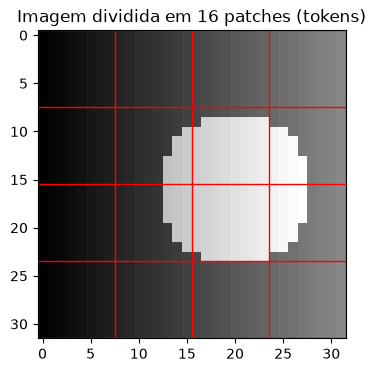

In [32]:
yy, xx = torch.meshgrid(torch.arange(32), torch.arange(32), indexing="ij")
imagem = xx / 31 * 0.5 + ((yy - 16) ** 2 + (xx - 20) ** 2 < 64).float() * 0.5

patches = imagem.unfold(0, 8, 8).unfold(1, 8, 8).reshape(16, 64)  # 16 patches, 64 pixels cada
torch.manual_seed(SEMENTE)
projecao = nn.Linear(64, 16)
posicao = nn.Parameter(torch.randn(16, 16) * 0.02)
tokens_imagem = (projecao(patches) + posicao).unsqueeze(0)  # (1, 16 tokens, 16 dim)

bloco_visual = nn.TransformerEncoderLayer(16, 2, 32, dropout=0.0, batch_first=True).eval()
with torch.no_grad():
    saida_visual = bloco_visual(tokens_imagem)
print(f"imagem {tuple(imagem.shape)} -> patches {tuple(patches.shape)} -> "
      f"tokens {tuple(tokens_imagem.shape)} -> saída do Transformer {tuple(saida_visual.shape)}")

plt.figure(figsize=(4, 4))
plt.imshow(imagem, cmap="gray")
for k in range(0, 33, 8):
    plt.axhline(k - 0.5, color="red", lw=1)
    plt.axvline(k - 0.5, color="red", lw=1)
plt.title("Imagem dividida em 16 patches (tokens)")
plt.grid(False)
plt.show()

**Interpretação.** A imagem virou uma sequência de 16 vetores, e o mesmo bloco Transformer do capítulo 3 a processa sem alteração. Só o encoder de entrada mudou.

No áudio, a onda sonora costuma virar um **espectrograma**, que mostra as frequências presentes a cada instante. Cada coluna (quadro) vira um token. Usamos um sinal sintético: 0,5 s de 440 Hz, seguidos de 0,5 s de 880 Hz.

sinal: 8000 amostras -> espectrograma (129, 63) (frequências, quadros)
Cada um dos 63 quadros vira um token de 129 números.


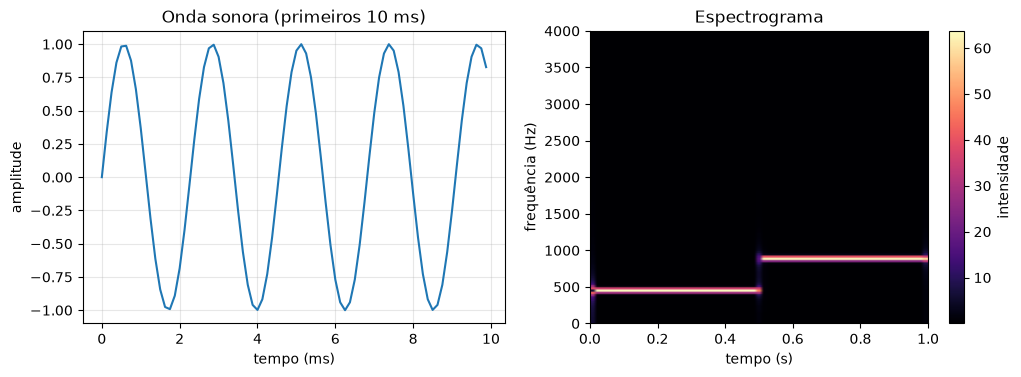

In [33]:
taxa = 8000
t = torch.arange(taxa) / taxa
frequencia = torch.where(t < 0.5, 440.0, 880.0)
sinal = torch.sin(2 * math.pi * frequencia * t)

espectro = torch.stft(sinal, n_fft=256, hop_length=128, window=torch.hann_window(256), return_complex=True).abs()
print(f"sinal: {sinal.shape[0]} amostras -> espectrograma {tuple(espectro.shape)} (frequências, quadros)")
print(f"Cada um dos {espectro.shape[1]} quadros vira um token de {espectro.shape[0]} números.")

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
eixos[0].plot(t[:80] * 1000, sinal[:80])
eixos[0].set(title="Onda sonora (primeiros 10 ms)", xlabel="tempo (ms)", ylabel="amplitude")
im = eixos[1].imshow(espectro, origin="lower", aspect="auto", cmap="magma",
                     extent=[0, 1, 0, taxa / 2])
eixos[1].set(title="Espectrograma", xlabel="tempo (s)", ylabel="frequência (Hz)")
eixos[1].grid(False)
fig.colorbar(im, ax=eixos[1], label="intensidade")
plt.show()

**Interpretação.** O espectrograma mostra uma faixa em 440 Hz até 0,5 s e outra em 880 Hz depois. A informação misturada na onda aparece separada, e é isso que o encoder de áudio entrega ao Transformer.

Para relacionar imagem e legenda, os dois encoders precisam produzir vetores no **mesmo espaço**. O **CLIP** faz isso com **aprendizado contrastivo**: aproxima os pares corretos e afasta os incorretos. Reproduzimos a ideia em miniatura, com imagens 8×8 de listras horizontais, verticais e diagonais.

Acurácia imagem -> legenda correta: 0.3% (antes) -> 100.0% (depois)


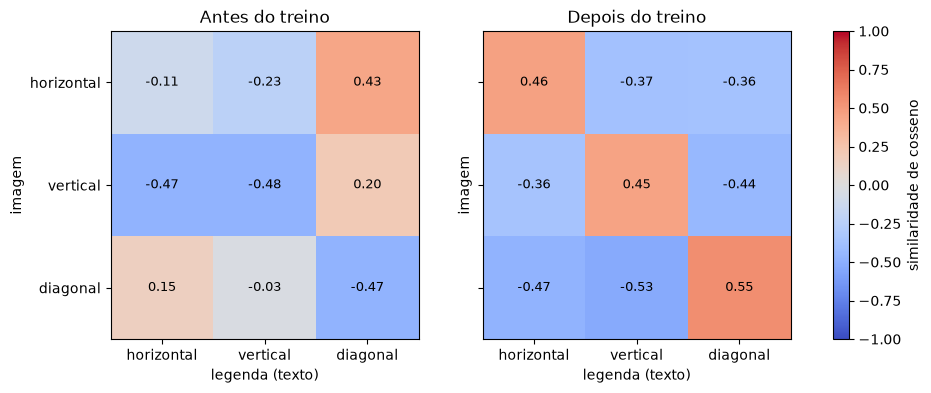

In [34]:
torch.manual_seed(SEMENTE)
nomes_padroes = ["horizontal", "vertical", "diagonal"]
base = torch.zeros(3, 8, 8)
base[0, ::2, :] = 1
base[1, :, ::2] = 1
base[2] = torch.eye(8)
base = base.reshape(3, 64)


def imagens_ruidosas(classes):
    return base[classes] + 0.3 * torch.randn(len(classes), 64)


codificador_imagem = nn.Linear(64, 8)
codificador_texto = nn.Embedding(3, 8)


def matriz_similaridade(imagens, ids_texto):
    zi = F.normalize(codificador_imagem(imagens), dim=-1)
    zt = F.normalize(codificador_texto(ids_texto), dim=-1)
    return zi @ zt.T


def acuracia_clip(n=300):
    classes = torch.randint(0, 3, (n,))
    with torch.no_grad():
        previsto = matriz_similaridade(imagens_ruidosas(classes), torch.arange(3)).argmax(1)
    return (previsto == classes).float().mean().item()


with torch.no_grad():
    sim_antes = matriz_similaridade(base, torch.arange(3)).numpy()
acc_antes_clip = acuracia_clip()

otim = torch.optim.Adam(list(codificador_imagem.parameters()) + list(codificador_texto.parameters()), lr=0.05)
alvos_clip = torch.arange(3)
for _ in range(300):
    sims = matriz_similaridade(imagens_ruidosas(alvos_clip), alvos_clip) / 0.1  # temperatura do softmax
    perda = (F.cross_entropy(sims, alvos_clip) + F.cross_entropy(sims.T, alvos_clip)) / 2
    otim.zero_grad()
    perda.backward()
    otim.step()

with torch.no_grad():
    sim_depois = matriz_similaridade(base, torch.arange(3)).numpy()
print(f"Acurácia imagem -> legenda correta: {acc_antes_clip:.1%} (antes) -> {acuracia_clip():.1%} (depois)")

fig, eixos = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, sim, titulo in [(eixos[0], sim_antes, "Antes do treino"), (eixos[1], sim_depois, "Depois do treino")]:
    im = ax.imshow(sim, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(3), nomes_padroes)
    ax.set_yticks(range(3), nomes_padroes)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set(title=titulo, xlabel="legenda (texto)", ylabel="imagem")
    ax.grid(False)
fig.colorbar(im, ax=eixos, label="similaridade de cosseno")
plt.show()

**Interpretação.** Antes do treino, as similaridades são aleatórias e a acurácia inicial é arbitrária (o acaso seria 33%; nesta execução os pesos sorteados erraram quase sempre, o que é só coincidência). Depois, a **diagonal** fica forte e o resto fica baixo, inclusive para imagens novas com ruído.

Os modelos multimodais atuais seguem essa receita em escala: um encoder visual gera tokens que entram na mesma sequência do texto e passam por um decoder.

> **Simplificação:** usamos encoders lineares, 3 classes e imagens sintéticas. Modelos reais usam Transformers profundos e centenas de milhões de pares imagem-legenda.

# 10. Ciclo de vida da IA

Os capítulos anteriores formam um ciclo contínuo, resumido abaixo.

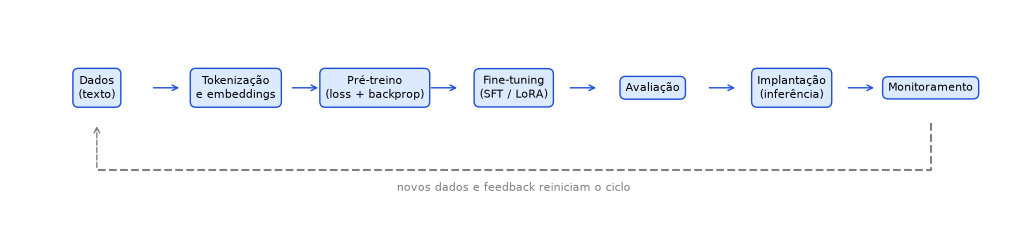

In [35]:
etapas = ["Dados\n(texto)", "Tokenização\ne embeddings", "Pré-treino\n(loss + backprop)", "Fine-tuning\n(SFT / LoRA)",
          "Avaliação", "Implantação\n(inferência)", "Monitoramento"]
fig, ax = plt.subplots(figsize=(13, 2.8))
for i, nome in enumerate(etapas):
    ax.text(i * 1.6, 0.5, nome, ha="center", va="center", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.5", fc="#dbeafe", ec="#1d4ed8"))
    if i < len(etapas) - 1:
        ax.annotate("", xy=((i + 1) * 1.6 - 0.62, 0.5), xytext=(i * 1.6 + 0.62, 0.5),
                    arrowprops=dict(arrowstyle="->", color="#1d4ed8"))
fim = (len(etapas) - 1) * 1.6
ax.plot([fim, fim, 0], [0.32, 0.08, 0.08], color="gray", ls="--")           # volta ao início
ax.annotate("", xy=(0, 0.32), xytext=(0, 0.08), arrowprops=dict(arrowstyle="->", color="gray", ls="--"))
ax.text(fim / 2, 0.02, "novos dados e feedback reiniciam o ciclo", ha="center", va="top", fontsize=8, color="gray")
ax.set(xlim=(-1, (len(etapas) - 1) * 1.6 + 1), ylim=(-0.2, 0.9))
ax.axis("off")
plt.show()

## Avaliação

Treinar não basta: é preciso saber se o modelo é bom em dados novos. Em modelos de linguagem, a métrica clássica é a **perplexidade**, a exponencial da loss de validação:

$$ \text{perplexidade} = e^{\text{loss}} $$

Ela indica entre quantos caracteres o modelo está em dúvida, em média. O pior caso é o chute uniforme, cuja perplexidade é igual ao tamanho do vocabulário.

In [36]:
V = len(caracteres)
print(f"{'modelo':28}{'loss':>8}{'perplexidade':>14}")
print(f"{'chute uniforme':28}{math.log(V):8.3f}{V:14.1f}")
for nome, X, y in [("nosso LM, dados de treino", X_tr, y_tr), ("nosso LM, dados de validação", X_va, y_va)]:
    perda = perda_media(lm, X, y)
    print(f"{nome:28}{perda:8.3f}{math.exp(perda):14.1f}")

modelo                          loss  perplexidade
chute uniforme                 3.258          26.0
nosso LM, dados de treino      0.189           1.2
nosso LM, dados de validação   0.211           1.2


**Interpretação.** As perplexidades de treino (≈ 1,21) e de validação (≈ 1,23) são próximas e muito menores que a do chute uniforme (26): em média, o modelo hesita entre pouco mais de um caractere. Isso vale para esta gramática simples. A pequena diferença já indica um começo de memorização. Se a validação fosse bem pior, teríamos *overfitting* claro, e por isso a avaliação usa sempre dados separados do treino. Em LLMs reais, entram também benchmarks, testes com humanos e verificações de segurança, pois boa perplexidade não garante respostas úteis ou seguras.

## Implantação

Em produção, importam o **tamanho** e a **latência**. A **quantização** guarda os pesos como inteiros de 8 bits (`int8`) no lugar de `float32`, com uma escala para recuperar os valores.

In [37]:
def quantizar_int8(tensor):
    escala = tensor.abs().max() / 127
    return torch.round(tensor / escala).to(torch.int8), escala


lm_int8 = deepcopy(lm)
bytes_fp32 = bytes_int8 = 0
with torch.no_grad():
    for p in lm_int8.parameters():
        q, escala = quantizar_int8(p)
        bytes_fp32 += p.numel() * 4
        bytes_int8 += p.numel() * 1 + 4          # pesos int8 + 1 escala float32
        p.copy_(q.float() * escala)              # volta a float só para avaliar o erro

print(f"Tamanho: {bytes_fp32 / 1024:.1f} KB (float32) -> {bytes_int8 / 1024:.1f} KB (int8)")
print(f"Perda de validação: {perda_media(lm, X_va, y_va):.4f} (float32) | {perda_media(lm_int8, X_va, y_va):.4f} (int8)")


def latencia(modelo, repeticoes=300):
    entrada = X_va[:1]
    inicio = time.perf_counter()
    with torch.no_grad():
        for _ in range(repeticoes):
            modelo(entrada)
    return (time.perf_counter() - inicio) / repeticoes * 1000


print(f"Latência de uma previsão (CPU): {latencia(lm):.3f} ms por caractere gerado")

Tamanho: 63.2 KB (float32) -> 15.8 KB (int8)
Perda de validação: 0.2106 (float32) | 0.2112 (int8)
Latência de uma previsão (CPU): 0.127 ms por caractere gerado


**Interpretação.** O modelo ficou cerca de 4 vezes menor e a perda de validação praticamente não mudou. É isso que torna viáveis os modelos de 8 e 4 bits da tabela do capítulo 5. (Aqui os pesos voltaram a `float` só para medir o erro de arredondamento. Em produção, os motores de inferência calculam direto com os inteiros.)

A latência é medida por token: uma resposta de 200 tokens executa o modelo 200 vezes, por isso a velocidade por token é uma métrica central.

## Evolução

Depois de implantado, o modelo envelhece: os dados mudam e deixam de se parecer com os do treino (*data drift*). O ciclo se fecha com monitoramento, coleta de feedback, novo fine-tuning (como o LoRA) ou atualização da base do RAG, e nova avaliação antes de cada versão.

## Revisão: o caminho completo

| Etapa | Conceito | O que vimos no notebook |
|---|---|---|
| Entrada | Tokenização, embeddings, posição | texto virou IDs, vetores e padrões de posição |
| Arquitetura | Atenção, Multi-Head, Encoder/Decoder | Q/K/V, máscara causal e bloco Transformer |
| Aprendizado | Loss, backprop, gradiente | pesos mudaram e a loss caiu |
| Memória | Parâmetros, tensores, checkpoints | `state_dict` salvo e recarregado |
| Adaptação | Transfer learning, SFT, LoRA | poucos parâmetros treinados sobre um modelo base |
| Uso | Logits, softmax, temperatura | texto gerado caractere a caractere |
| Aplicação | Prompt, few-shot, RAG | contexto muda a saída e injeta conhecimento |
| Além do texto | Patches, espectrogramas, contrastivo | imagem e áudio como sequências de vetores |
| Operação | Perplexidade, quantização, monitoramento | avaliação, tamanho e latência |

Os LLMs reais diferem dos modelos deste notebook pela **escala** e pela engenharia, mas os princípios são os mesmos: transformar o mundo em números, ajustar pesos para reduzir um erro e sortear a próxima peça a partir de probabilidades.